## Evolution of the conversion parameter

In this file, we will study how $\gamma_{con}$ evolves and how it is affected by the various parameters.
We are in particular interested to look at the first order term for the source term

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt
from plot_utils import set_size, set_colors, width_jcap, sci_formatter
plt.style.use('my_style.mplstyle')

In [12]:
def extract_data_from_files(file_name, num_columns):
    """Extract data for the evolution of the various parameters"""
    
    data = np.loadtxt(file_name, comments='#')  

    z = data[:, 0]
    pars = [data[:, i+1] for i in range(0, num_columns)]

    return np.array(z), np.array(pars)

In [13]:
z, (xi_e, _ , gamma_con, dlngamma_noXe, dlngamma) = extract_data_from_files('custom_redshift_info.dat_ymax5_lmax15_adiabatic.dat', 5)
z, (Tcmb, H, dlngamma_T, dlngamma_H) = extract_data_from_files('custom_redshift_info.dat_ymax5_lmax15_adiabatic_TH.dat', 4)
#z, (H, dlngamma_H) = extract_data_from_files('custom_redshift_info.dat_ymax5_lmax15_adiabatic_H.dat', 2)
z_e, (Xe, dlngamma_Xe) = extract_data_from_files('custom_redshift_info.dat_ymax5_lmax15_adiabatic_Xe.dat', 2)


The displacement from one at low redshift is due to the fact that for small z we have:
$\frac{d ln(1+z)}{d lnz} \simeq \frac{d z}{d lnz}$

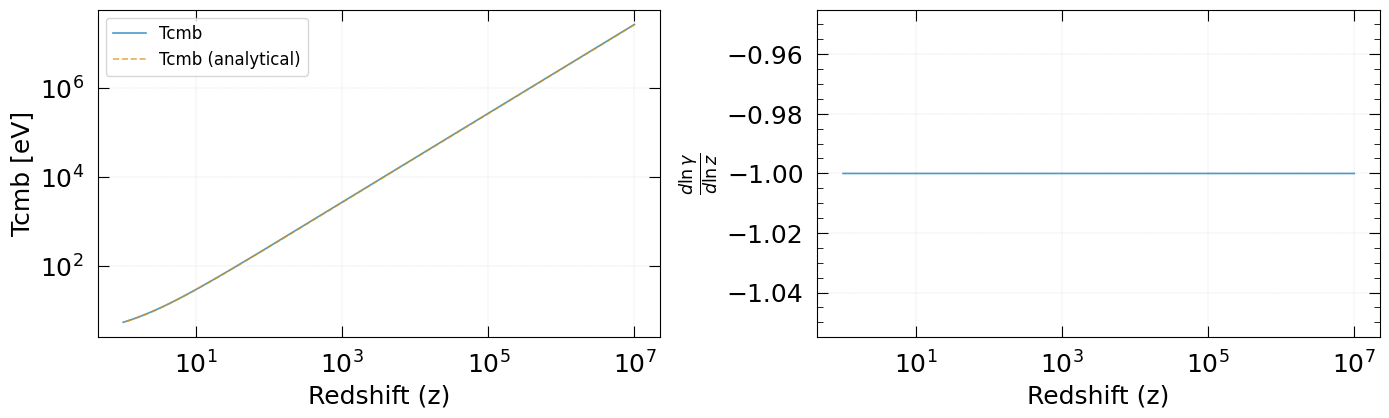

In [14]:
colors = set_colors(5, palette="sns:colorblind")
#colors = tc.colorsets['vibrant']

fig, ax = plt.subplots(1, 2, figsize=mplt.set_size(mplt.width*2, 1, (1,2)))

ax[0].plot(z, Tcmb, label = "Tcmb", color=colors[0], alpha=0.7, linestyle="-")
ax[0].plot(z , 2.7 * (1+z), label = "Tcmb (analytical)", color=colors[1], alpha=0.7, linestyle="--")
ax[1].plot(z, dlngamma_T, color=colors[0], alpha=0.7, linestyle="-")


mplt.set_ticks(ax[0])
mplt.set_labels(ax[0], x_label="Redshift (z)", x_log=True, y_label="Tcmb [eV]", y_log=True, title=None)

mplt.set_ticks(ax[1])
mplt.set_labels(ax[1], x_label="Redshift (z)", x_log=True, y_label="$\\frac{d\\ln \\gamma}{d\\ln z}$", y_log=False, title=None)

ax[0].legend()
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

Note that the free electron fraction exceeds one because it is defined neglecting helium, but there is helium in the Universe.

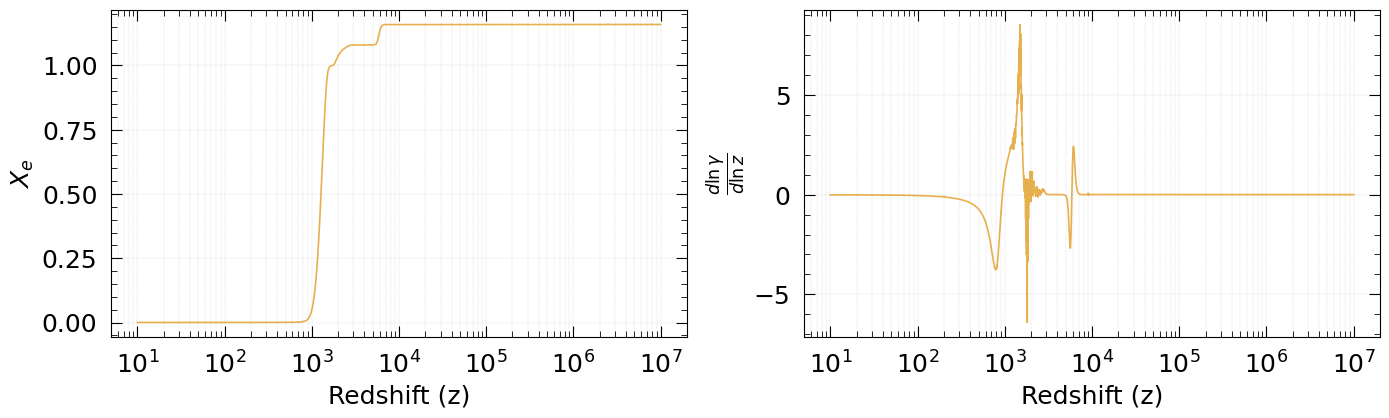

In [15]:


fig, ax = plt.subplots(1, 2, figsize=mplt.set_size(mplt.width*2, 1, (1,2)))
ax[0].plot(z_e, Xe, color=colors[1], alpha=0.7, linestyle="-")
ax[1].plot(z_e, dlngamma_Xe, color=colors[1], alpha=0.7, linestyle="-")

mplt.set_ticks(ax[0])
mplt.set_labels(ax[0], x_label="Redshift (z)", x_log=True, y_label="$X_e$", y_log=False, title=None)

mplt.set_ticks(ax[1])
mplt.set_labels(ax[1], x_label="Redshift (z)", x_log=True, y_label="$\\frac{d\\ln \\gamma}{d\\ln z}$", y_log=False, title=None)

plt.show()

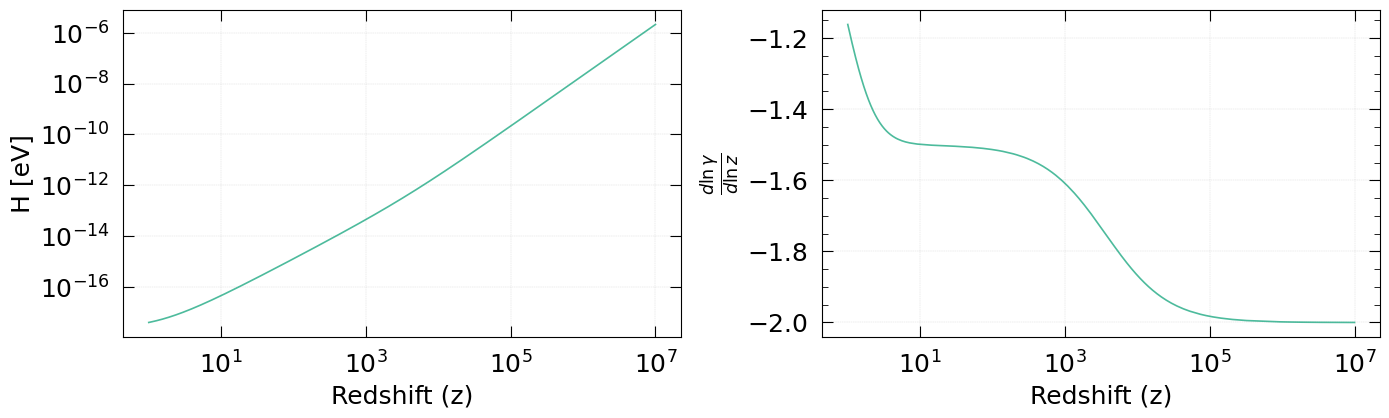

In [16]:

fig, ax = plt.subplots(1, 2, figsize=mplt.set_size(mplt.width*2, 1, (1,2)))
ax[0].plot(z, H, color=colors[2], alpha=0.7, linestyle="-")
ax[1].plot(z, dlngamma_H, color=colors[2], alpha=0.7, linestyle="-")

mplt.set_ticks(ax[0])
mplt.set_labels(ax[0], x_label="Redshift (z)", x_log=True, y_label="H [eV]", y_log=True, title=None)

mplt.set_ticks(ax[1])
mplt.set_labels(ax[1], x_label="Redshift (z)", x_log=True, y_label="$\\frac{d\\ln \\gamma}{d\\ln z}$", y_log=False, title=None)

plt.show()

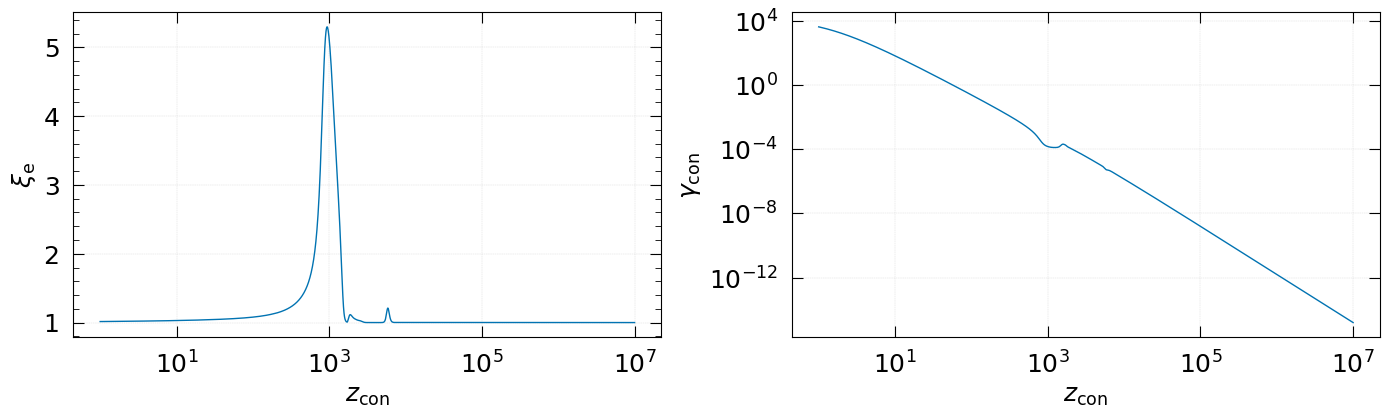

In [17]:

colors0 = set_colors(3, palette="tol:bright")
fig, ax = plt.subplots(1, 2, figsize=mplt.set_size(mplt.width*2, 1, (1,2)))
ax[0].plot(z, xi_e, color=colors[0], linewidth=1, linestyle="-")
ax[1].plot(z, gamma_con, color=colors[0], linewidth=1, linestyle="-")

mplt.set_ticks(ax[0])
mplt.set_labels(ax[0], x_label="$z_{\\rm con}$", x_log=True, y_label="$\\xi_{\\rm e}$", y_log=False, title=None)

mplt.set_ticks(ax[1])
mplt.set_labels(ax[1], x_label="$z_{\\rm con}$", x_log=True, y_label="$\\gamma_{\\rm con}$", y_log=True, title=None)

plt.savefig('outputs/gamma_evolution.pdf', dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [18]:
z_start = 8000
z_end = 4000
z_start2 = 2200
z_end2 = 1500
z_end3 = 500

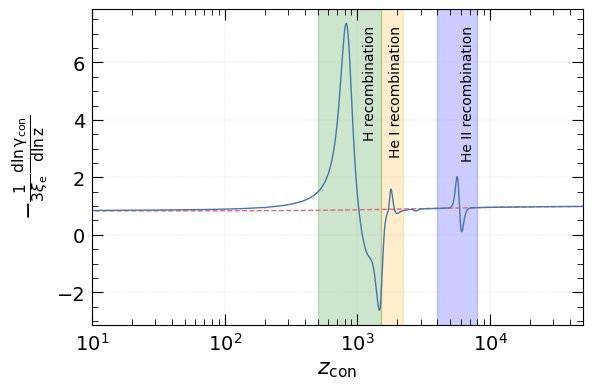

In [19]:

fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap*1, 1, (1,1), 8/12))
ax.plot(z, -dlngamma_noXe/3, color=colors0[1], linewidth=1, linestyle="--", label="no $X_{\\rm e}$ evolution")
ax.plot(z, -dlngamma/3*xi_e, color=colors0[0], linewidth=1, linestyle="-")

ax.set_xlabel("$z_{\\rm con}$")
ax.set_ylabel("$ - \\frac{1}{3 \\xi_{\\rm e} }\\frac{\\rm d \\ln \\gamma_{\\rm con}}{\\rm d\\ln z}$")
ax.set_xscale("log")
ax.set_yscale("linear")

ax.axvspan(z_start, z_end, alpha=0.2, color='blue')
ax.axvspan(z_start2, z_end2, alpha=0.2, color='orange')
ax.axvspan(z_end2, z_end3, alpha=0.2, color='green')

ax.set_xlim(10, 5e4)

# Get y-axis limits for positioning text
ylim = ax.get_ylim()
y_upper = ylim[0] + 0.95 * (ylim[1] - ylim[0])

# Add vertical text annotations within each band
ax.text(z_end * 1.7, y_upper, 'He II recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)
ax.text(z_end2 * 1.3, y_upper, 'He I recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)
ax.text(z_end3 * 2.5, y_upper, 'H recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)

plt.savefig('outputs/gamma_evolution0.pdf', dpi=300, bbox_inches="tight")
plt.show()

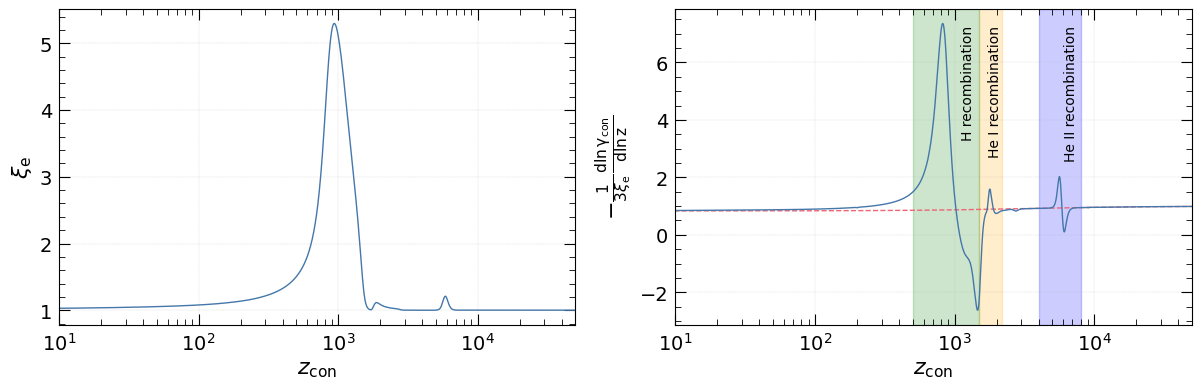

In [20]:

fig, ax = plt.subplots(1, 2, figsize=set_size(width_jcap*2, 1, (1,2), 8/12))
ax[0].plot(z, xi_e, color=colors0[0], linewidth=1, linestyle="-")
ax[1].plot(z, -dlngamma_noXe/3, color=colors0[1], linewidth=1, linestyle="--", label="no $X_{\\rm e}$ evolution")
ax[1].plot(z, -dlngamma/3*xi_e, color=colors0[0], linewidth=1, linestyle="-")

ax[0].set_xlabel("$z_{\\rm con}$")
ax[0].set_ylabel("$\\xi_{\\rm e}$")
ax[0].set_xscale("log")
ax[0].set_yscale("linear")


ax[1].set_xlabel("$z_{\\rm con}$")
ax[1].set_ylabel("$ - \\frac{1}{3 \\xi_{\\rm e} }\\frac{\\rm d \\ln \\gamma_{\\rm con}}{\\rm d\\ln z}$")
ax[1].set_xscale("log")
ax[1].set_yscale("linear")

ax[1].axvspan(z_start, z_end, alpha=0.2, color='blue')
ax[1].axvspan(z_start2, z_end2, alpha=0.2, color='orange')
ax[1].axvspan(z_end2, z_end3, alpha=0.2, color='green')

ax[0].set_xlim(10, 5e4)
ax[1].set_xlim(10, 5e4)

# Get y-axis limits for positioning text
ylim = ax[1].get_ylim()
y_upper = ylim[0] + 0.95 * (ylim[1] - ylim[0])

# Add vertical text annotations within each band
ax[1].text(z_end * 1.7, y_upper, 'He II recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)
ax[1].text(z_end2 * 1.3, y_upper, 'He I recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)
ax[1].text(z_end3 * 2.5, y_upper, 'H recombination', rotation=90, 
           verticalalignment='top', horizontalalignment='center', fontsize=10)

plt.savefig('outputs/gamma_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

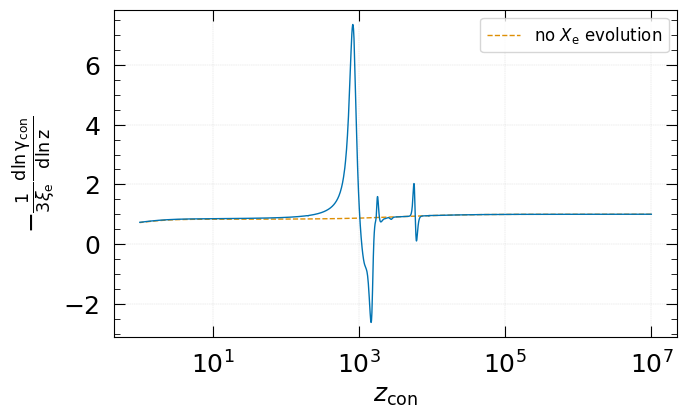

In [21]:

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(z, -dlngamma_noXe/3, color=colors[1], linewidth=1, linestyle="--", label="no $X_{\\rm e}$ evolution")
#ax.plot(z, xi_e, color=colors[1], alpha=0.7, linestyle="-", label="$\\xi_e$")
ax.plot(z, -dlngamma/3*xi_e, color=colors[0], linewidth=1, linestyle="-")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$z_{\\rm con}$", x_log=True, y_label="$ - \\frac{1}{3 \\xi_{\\rm e} }\\frac{\\rm d \\ln \\gamma_{\\rm con}}{\\rm d\\ln z}$", y_log=False, title=None)
plt.legend()
plt.savefig('outputs/dgamma_evolution.pdf', dpi=300, bbox_inches="tight")

plt.show()

